In [ ]:
import torch
from torch import nn
from torch.utils.data import DataLoader
from torchvision import transforms, models
from torchvision.models import ViT_B_16_Weights

from datasets import load_dataset
from torchinfo import summary
from tqdm.auto import tqdm
from collections import Counter
from pathlib import Path
from PIL import Image

import matplotlib.pyplot as plt
import random

In [5]:
device = "cuda" if torch.cuda.is_available() else "cpu"
device

'cuda'

In [ ]:
dataset = load_dataset("JJMack/pokemon-classification-gen1-9")

In [7]:
print(dataset)

DatasetDict({
    train: Dataset({
        features: ['file_name', 'image_data', 'label', 'name', 'generation', 'Type 1', 'Type 2', 'HP', 'Attack', 'Defense', 'Sp.Attack', 'Sp.Defense', 'Speed', 'shiny'],
        num_rows: 13188
    })
    validation: Dataset({
        features: ['file_name', 'image_data', 'label', 'name', 'generation', 'Type 1', 'Type 2', 'HP', 'Attack', 'Defense', 'Sp.Attack', 'Sp.Defense', 'Speed', 'shiny'],
        num_rows: 2198
    })
    test: Dataset({
        features: ['file_name', 'image_data', 'label', 'name', 'generation', 'Type 1', 'Type 2', 'HP', 'Attack', 'Defense', 'Sp.Attack', 'Sp.Defense', 'Speed', 'shiny'],
        num_rows: 2530
    })
})


In [8]:
num_classes = len(dataset["train"].features["label"].names)

In [9]:
num_classes

1027

In [ ]:
sizes = Counter()
channels = Counter()

for split in dataset:
    for sample in dataset[split]:
        img = sample["image_data"]
        sizes[img.size] += 1
        channels[img.mode] += 1

print("Image Sizes:")
for size, count in sizes.most_common():
    print(f"{size}: {count}")

print("\nImage Channels:")
for channel, count in channels.most_common():
    print(f"{channel}: {count}")

Image Sizes:
(256, 256): 17886
(250, 250): 21
(185, 185): 4
(240, 240): 3
(360, 360): 1
(700, 700): 1

Image Channels:
RGBA: 14116
P: 3785
RGB: 15


In [ ]:
weights = ViT_B_16_Weights.DEFAULT
auto_transforms = weights.transforms()

In [ ]:
def preprocess_image(image):
    image = image.convert("RGBA")
    background = Image.new("RGB", image.size, (255, 255, 255))
    background.paste(image, mask=image.getchannel("A"))
    return auto_transforms(background)

In [ ]:
def transform_batch(batch):
    batch["pixel_values"] = [preprocess_image(img) for img in batch["image_data"]]
    return batch

dataset = dataset.with_transform(transform_batch)

In [36]:
def collate_fn(batch):
    images = torch.stack([item["pixel_values"] for item in batch])
    labels = torch.tensor([item["label"] for item in batch])
    return images, labels

train_loader = DataLoader(dataset["train"], batch_size=32, shuffle=True, collate_fn=collate_fn)
val_loader = DataLoader(dataset["validation"], batch_size=32, collate_fn=collate_fn)
test_loader = DataLoader(dataset["test"], batch_size=32, collate_fn=collate_fn)

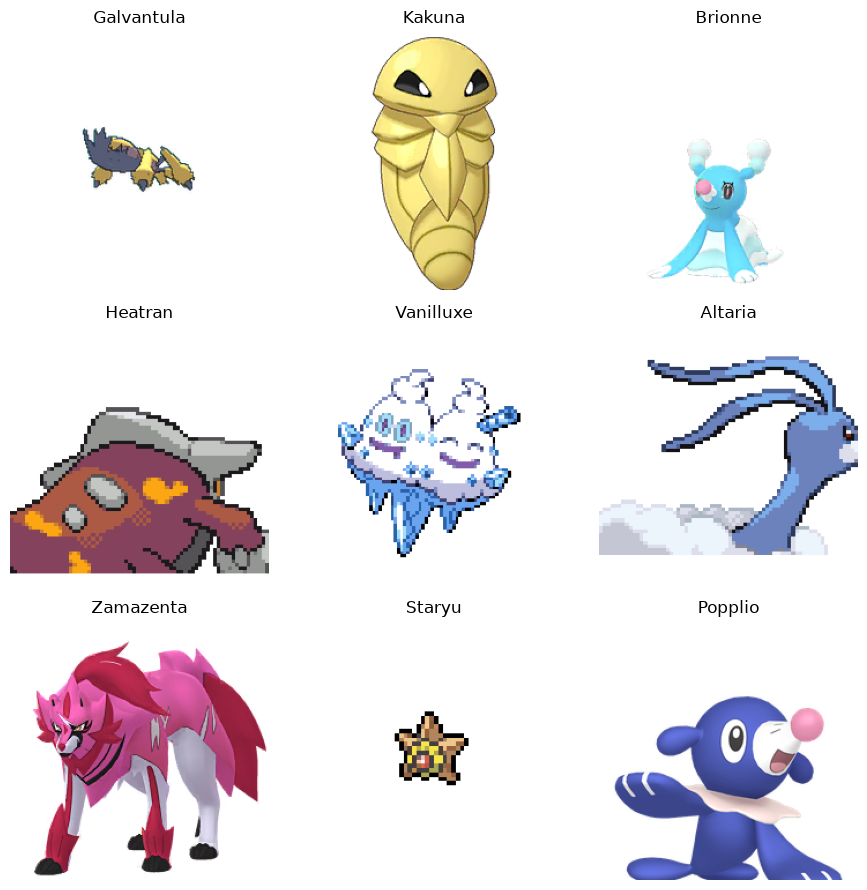

Batch shape: torch.Size([32, 3, 224, 224])
Single image shape: torch.Size([3, 224, 224])


In [ ]:
images, labels = next(iter(train_loader))

fig, axes = plt.subplots(3, 3, figsize=(9, 9))

for i, ax in enumerate(axes.flat):
    img = images[i].permute(1, 2, 0)
    img = img * torch.tensor(auto_transforms.std) + torch.tensor(auto_transforms.mean)
    ax.imshow(img.clamp(0, 1))
    class_name = dataset["train"].features["label"].int2str(labels[i].item())
    ax.set_title(class_name)
    ax.axis("off")

plt.tight_layout()
plt.show()

print("Batch shape:", images.shape)
print("Single image shape:", images[0].shape)

In [16]:
model = models.vit_b_16(weights=weights)

In [17]:
model

VisionTransformer(
  (conv_proj): Conv2d(3, 768, kernel_size=(16, 16), stride=(16, 16))
  (encoder): Encoder(
    (dropout): Dropout(p=0.0, inplace=False)
    (layers): Sequential(
      (encoder_layer_0): EncoderBlock(
        (ln_1): LayerNorm((768,), eps=1e-06, elementwise_affine=True)
        (self_attention): MultiheadAttention(
          (out_proj): NonDynamicallyQuantizableLinear(in_features=768, out_features=768, bias=True)
        )
        (dropout): Dropout(p=0.0, inplace=False)
        (ln_2): LayerNorm((768,), eps=1e-06, elementwise_affine=True)
        (mlp): MLPBlock(
          (0): Linear(in_features=768, out_features=3072, bias=True)
          (1): GELU(approximate='none')
          (2): Dropout(p=0.0, inplace=False)
          (3): Linear(in_features=3072, out_features=768, bias=True)
          (4): Dropout(p=0.0, inplace=False)
        )
      )
      (encoder_layer_1): EncoderBlock(
        (ln_1): LayerNorm((768,), eps=1e-06, elementwise_affine=True)
        (self_a

In [ ]:
summary(model=model,
         input_size=(1, 3, 224, 224),
         col_names=["input_size", "output_size", "num_params", "trainable"],
         col_width=20,
         row_settings=["var_names"])

Layer (type (var_name))                                      Input Shape          Output Shape         Param #              Trainable
VisionTransformer (VisionTransformer)                        [1, 3, 224, 224]     [1, 1000]            768                  True
├─Conv2d (conv_proj)                                         [1, 3, 224, 224]     [1, 768, 14, 14]     590,592              True
├─Encoder (encoder)                                          [1, 197, 768]        [1, 197, 768]        151,296              True
│    └─Dropout (dropout)                                     [1, 197, 768]        [1, 197, 768]        --                   --
│    └─Sequential (layers)                                   [1, 197, 768]        [1, 197, 768]        --                   True
│    │    └─EncoderBlock (encoder_layer_0)                   [1, 197, 768]        [1, 197, 768]        7,087,872            True
│    │    └─EncoderBlock (encoder_layer_1)                   [1, 197, 768]        [1, 197, 768

In [19]:
for param in model.parameters():
  param.requires_grad = False

In [20]:
model.heads = nn.Linear(
  in_features=model.hidden_dim,
  out_features=num_classes
)

model = model.to(device)

In [21]:
summary(model=model,
         input_size=(1, 3, 224, 224),
         col_names=["input_size", "output_size", "num_params", "trainable"],
         col_width=20,
         row_settings=["var_names"])

Layer (type (var_name))                                      Input Shape          Output Shape         Param #              Trainable
VisionTransformer (VisionTransformer)                        [1, 3, 224, 224]     [1, 1027]            768                  Partial
├─Conv2d (conv_proj)                                         [1, 3, 224, 224]     [1, 768, 14, 14]     (590,592)            False
├─Encoder (encoder)                                          [1, 197, 768]        [1, 197, 768]        151,296              False
│    └─Dropout (dropout)                                     [1, 197, 768]        [1, 197, 768]        --                   --
│    └─Sequential (layers)                                   [1, 197, 768]        [1, 197, 768]        --                   False
│    │    └─EncoderBlock (encoder_layer_0)                   [1, 197, 768]        [1, 197, 768]        (7,087,872)          False
│    │    └─EncoderBlock (encoder_layer_1)                   [1, 197, 768]        [1, 1

In [22]:
loss_fn = nn.CrossEntropyLoss()

optimizer = torch.optim.AdamW(params=model.heads.parameters(),
                              lr=1e-3,
                              weight_decay=1e-4)

In [ ]:
epochs = 5

for epoch in range(epochs):
    model.train()
    train_loss = 0
    train_correct = 0
    train_total = 0

    progress = tqdm(train_loader, desc=f"Epoch {epoch+1}/{epochs}")

    for images, labels in progress:
        images, labels = images.to(device), labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)
        loss = loss_fn(outputs, labels)

        loss.backward()
        optimizer.step()

        train_loss += loss.item() * labels.size(0)
        train_correct += (outputs.argmax(1) == labels).sum().item()
        train_total += labels.size(0)

        progress.set_postfix(
            loss=f"{train_loss/train_total:.4f}",
            acc=f"{100*train_correct/train_total:.2f}%"
        )

    print(
        f"Epoch {epoch+1}: "
        f"Loss={train_loss/train_total:.4f}, "
        f"Accuracy={100*train_correct/train_total:.2f}%"
    )

Epoch 1/5: 100%|██████████| 413/413 [04:57<00:00,  1.39it/s, acc=24.43%, loss=5.2669]


Epoch 1: Loss=5.2669, Accuracy=24.43%


Epoch 2/5: 100%|██████████| 413/413 [05:18<00:00,  1.30it/s, acc=73.01%, loss=2.0476]


Epoch 2: Loss=2.0476, Accuracy=73.01%


Epoch 3/5: 100%|██████████| 413/413 [05:30<00:00,  1.25it/s, acc=84.90%, loss=1.1732]


Epoch 3: Loss=1.1732, Accuracy=84.90%


Epoch 4/5: 100%|██████████| 413/413 [05:40<00:00,  1.21it/s, acc=89.04%, loss=0.8487]


Epoch 4: Loss=0.8487, Accuracy=89.04%


Epoch 5/5: 100%|██████████| 413/413 [05:12<00:00,  1.32it/s, acc=90.88%, loss=0.6815]

Epoch 5: Loss=0.6815, Accuracy=90.88%


In [27]:
torch.save(model.state_dict(), "pokemon_vit_feature_extraction.pth")

In [28]:
model.eval()

val_loss = 0
val_correct = 0
val_total = 0

with torch.inference_mode():
    for images, labels in tqdm(val_loader, desc="Validation"):
        images, labels = images.to(device), labels.to(device)

        outputs = model(images)
        loss = loss_fn(outputs, labels)

        val_loss += loss.item() * labels.size(0)
        val_correct += (outputs.argmax(1) == labels).sum().item()
        val_total += labels.size(0)

print(f"Validation Loss: {val_loss / val_total:.4f}")
print(f"Validation Accuracy: {100 * val_correct / val_total:.2f}%")

Validation: 100%|██████████| 69/69 [00:29<00:00,  2.36it/s]

Validation Loss: 1.4564
Validation Accuracy: 75.48%


In [29]:
wrong_images = []
wrong_labels = []
wrong_preds = []

model.eval()

with torch.inference_mode():
    for images, labels in tqdm(val_loader, desc="Finding mistakes"):
        outputs = model(images.to(device))
        preds = outputs.argmax(1).cpu()

        wrong = preds != labels

        wrong_images.extend(images[wrong])
        wrong_labels.extend(labels[wrong].tolist())
        wrong_preds.extend(preds[wrong].tolist())

        if len(wrong_images) >= 9:
            break

Finding mistakes:   1%|▏         | 1/69 [00:01<01:41,  1.50s/it]


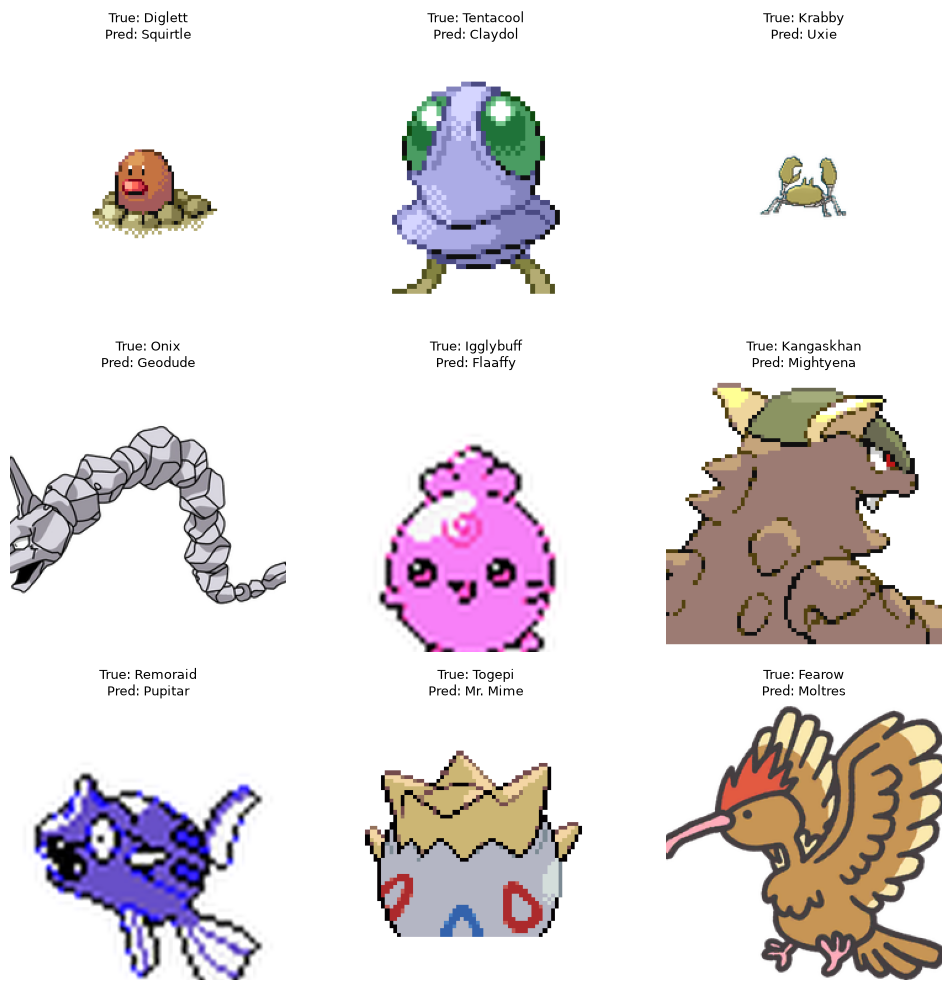

In [30]:
fig, axes = plt.subplots(3, 3, figsize=(10, 10))
class_names = dataset["train"].features["label"]

for i, ax in enumerate(axes.flat):
    img = wrong_images[i].permute(1, 2, 0)
    img = img * torch.tensor(auto_transforms.std) + torch.tensor(auto_transforms.mean)

    ax.imshow(img.clamp(0, 1))
    ax.set_title(
        f"True: {class_names.int2str(wrong_labels[i])}\n"
        f"Pred: {class_names.int2str(wrong_preds[i])}",
        fontsize=9
    )
    ax.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
# existing preprocessing: 256x256 -> CenterCrop(224x224)
# so, some predictions are not good due to pixel losses

In [ ]:
auto_transforms = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=weights.transforms().mean,
        std=weights.transforms().std
    )
])

In [37]:
model.eval()

val_loss = 0
val_correct = 0
val_total = 0

with torch.inference_mode():
    for images, labels in tqdm(val_loader, desc="Validation"):
        images, labels = images.to(device), labels.to(device)

        outputs = model(images)
        loss = loss_fn(outputs, labels)

        val_loss += loss.item() * labels.size(0)
        val_correct += (outputs.argmax(1) == labels).sum().item()
        val_total += labels.size(0)

print(f"Validation Loss: {val_loss / val_total:.4f}")
print(f"Validation Accuracy: {100 * val_correct / val_total:.2f}%")

Validation: 100%|██████████| 69/69 [00:29<00:00,  2.35it/s]

Validation Loss: 1.0949
Validation Accuracy: 79.53%


In [ ]:
# fine-tuning: unfreeze the last two transformer encoder blocks
# earlier layers remain frozen to preserve pretrained features
# the classification head also remains trainable

for param in model.encoder.layers[-2:].parameters():
    param.requires_grad = True

In [40]:
summary(model=model,
         input_size=(1, 3, 224, 224),
         col_names=["input_size", "output_size", "num_params", "trainable"],
         col_width=20,
         row_settings=["var_names"])

Layer (type (var_name))                                      Input Shape          Output Shape         Param #              Trainable
VisionTransformer (VisionTransformer)                        [1, 3, 224, 224]     [1, 1027]            768                  Partial
├─Conv2d (conv_proj)                                         [1, 3, 224, 224]     [1, 768, 14, 14]     (590,592)            False
├─Encoder (encoder)                                          [1, 197, 768]        [1, 197, 768]        151,296              Partial
│    └─Dropout (dropout)                                     [1, 197, 768]        [1, 197, 768]        --                   --
│    └─Sequential (layers)                                   [1, 197, 768]        [1, 197, 768]        --                   Partial
│    │    └─EncoderBlock (encoder_layer_0)                   [1, 197, 768]        [1, 197, 768]        (7,087,872)          False
│    │    └─EncoderBlock (encoder_layer_1)                   [1, 197, 768]        [

In [ ]:
# use a lower learning rate for pretrained encoder layers
# and a higher learning rate for the classification head.

optimizer = torch.optim.AdamW([
    {"params": model.encoder.layers[-2:].parameters(), "lr": 1e-5},
    {"params": model.heads.parameters(), "lr": 1e-4}
], weight_decay=1e-4)

In [ ]:
epochs = 5
best_val_acc = 0
history = []

for epoch in range(epochs):

    # Training
    model.train()
    train_loss = train_correct = train_total = 0

    for images, labels in tqdm(train_loader, desc=f"Epoch {epoch+1}/{epochs}"):
        images, labels = images.to(device), labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)
        loss = loss_fn(outputs, labels)

        loss.backward()
        optimizer.step()

        train_loss += loss.item() * labels.size(0)
        train_correct += (outputs.argmax(1) == labels).sum().item()
        train_total += labels.size(0)

    # Validation
    model.eval()
    val_loss = val_correct = val_total = 0

    with torch.inference_mode():
        for images, labels in val_loader:
            images, labels = images.to(device), labels.to(device)

            outputs = model(images)
            loss = loss_fn(outputs, labels)

            val_loss += loss.item() * labels.size(0)
            val_correct += (outputs.argmax(1) == labels).sum().item()
            val_total += labels.size(0)

    metrics = {
        "train_loss": train_loss / train_total,
        "train_acc": 100 * train_correct / train_total,
        "val_loss": val_loss / val_total,
        "val_acc": 100 * val_correct / val_total
    }

    history.append(metrics)

    if metrics["val_acc"] > best_val_acc:
        best_val_acc = metrics["val_acc"]
        torch.save(model.state_dict(), "pokemon_vit_finetuned_best.pth")

    print(
        f"Epoch {epoch+1}/{epochs} | "
        f"Train Loss: {metrics['train_loss']:.4f} | "
        f"Train Acc: {metrics['train_acc']:.2f}% | "
        f"Val Loss: {metrics['val_loss']:.4f} | "
        f"Val Acc: {metrics['val_acc']:.2f}%"
    )

print(f"\nBest Validation Accuracy: {best_val_acc:.2f}%")

Epoch 1/5: 100%|██████████| 413/413 [05:29<00:00,  1.25it/s]


Epoch 1/5 | Train Loss: 0.2985 | Train Acc: 94.79% | Val Loss: 0.7219 | Val Acc: 85.44%


Epoch 2/5: 100%|██████████| 413/413 [06:06<00:00,  1.13it/s]


Epoch 2/5 | Train Loss: 0.1669 | Train Acc: 97.19% | Val Loss: 0.6591 | Val Acc: 86.62%


Epoch 3/5: 100%|██████████| 413/413 [06:04<00:00,  1.13it/s]


Epoch 3/5 | Train Loss: 0.1086 | Train Acc: 98.48% | Val Loss: 0.6200 | Val Acc: 87.12%


Epoch 4/5: 100%|██████████| 413/413 [06:13<00:00,  1.11it/s]


Epoch 4/5 | Train Loss: 0.0707 | Train Acc: 99.31% | Val Loss: 0.5945 | Val Acc: 87.67%


Epoch 5/5: 100%|██████████| 413/413 [06:07<00:00,  1.12it/s]


Epoch 5/5 | Train Loss: 0.0457 | Train Acc: 99.72% | Val Loss: 0.5770 | Val Acc: 87.49%

Best Validation Accuracy: 87.67%


In [43]:
model.load_state_dict(
    torch.load("pokemon_vit_finetuned_best.pth",
               map_location=device,
               weights_only=True)
)

model.eval()

VisionTransformer(
  (conv_proj): Conv2d(3, 768, kernel_size=(16, 16), stride=(16, 16))
  (encoder): Encoder(
    (dropout): Dropout(p=0.0, inplace=False)
    (layers): Sequential(
      (encoder_layer_0): EncoderBlock(
        (ln_1): LayerNorm((768,), eps=1e-06, elementwise_affine=True)
        (self_attention): MultiheadAttention(
          (out_proj): NonDynamicallyQuantizableLinear(in_features=768, out_features=768, bias=True)
        )
        (dropout): Dropout(p=0.0, inplace=False)
        (ln_2): LayerNorm((768,), eps=1e-06, elementwise_affine=True)
        (mlp): MLPBlock(
          (0): Linear(in_features=768, out_features=3072, bias=True)
          (1): GELU(approximate='none')
          (2): Dropout(p=0.0, inplace=False)
          (3): Linear(in_features=3072, out_features=768, bias=True)
          (4): Dropout(p=0.0, inplace=False)
        )
      )
      (encoder_layer_1): EncoderBlock(
        (ln_1): LayerNorm((768,), eps=1e-06, elementwise_affine=True)
        (self_a

In [44]:
test_loss = test_correct = test_total = 0

with torch.inference_mode():
    for images, labels in tqdm(test_loader, desc="Testing"):
        images, labels = images.to(device), labels.to(device)

        outputs = model(images)
        loss = loss_fn(outputs, labels)

        test_loss += loss.item() * labels.size(0)
        test_correct += (outputs.argmax(1) == labels).sum().item()
        test_total += labels.size(0)

print(f"Test Loss: {test_loss / test_total:.4f}")
print(f"Test Accuracy: {100 * test_correct / test_total:.2f}%")

Testing: 100%|██████████| 80/80 [00:36<00:00,  2.19it/s]

Test Loss: 0.6504
Test Accuracy: 86.32%


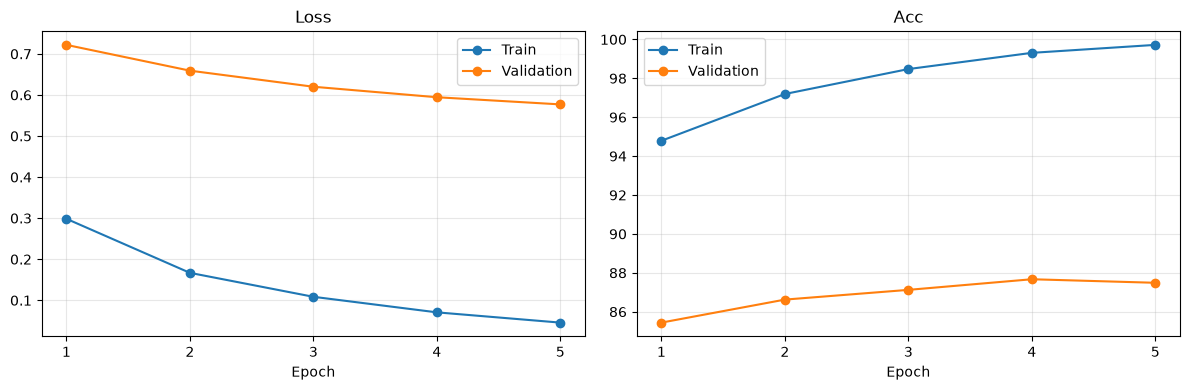

In [46]:
epochs_range = range(1, len(history) + 1)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for ax, metric in zip(axes, ["loss", "acc"]):
    ax.plot(epochs_range, [h[f"train_{metric}"] for h in history], marker="o", label="Train")
    ax.plot(epochs_range, [h[f"val_{metric}"] for h in history], marker="o", label="Validation")
    ax.set_title(metric.capitalize())
    ax.set_xlabel("Epoch")
    ax.set_xticks(epochs_range)
    ax.legend()
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

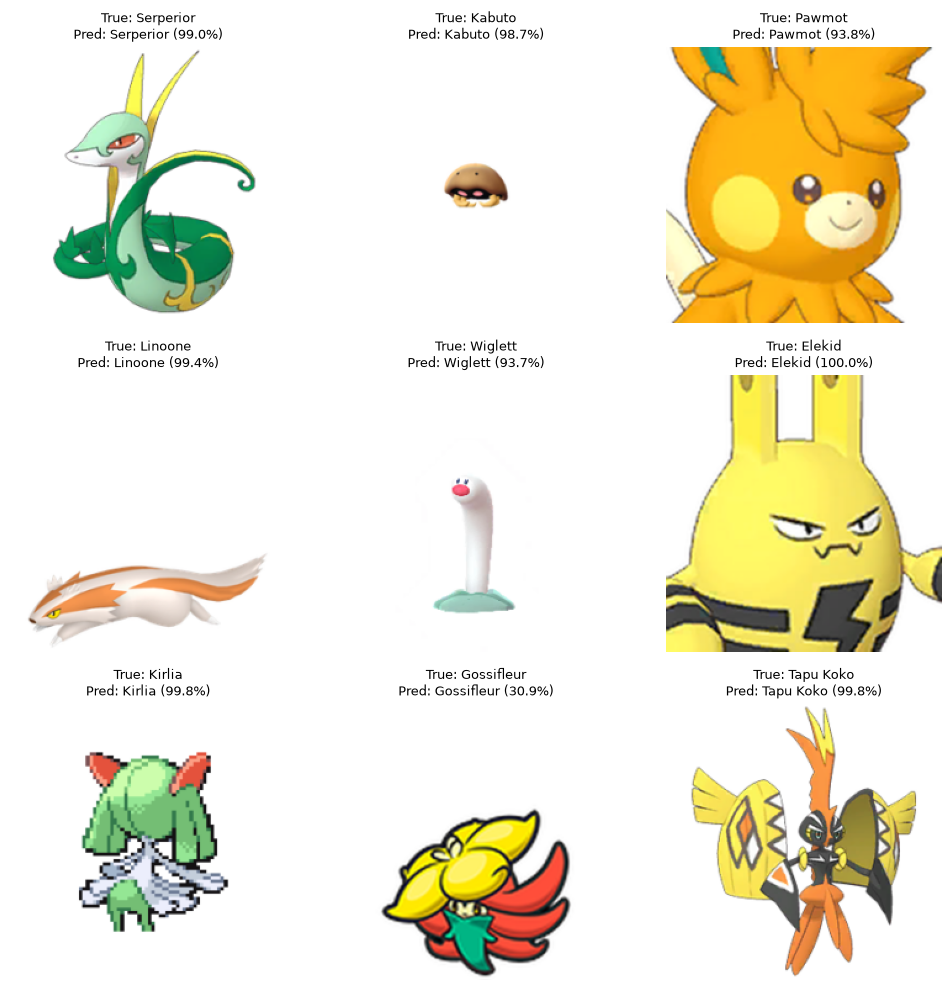

In [ ]:
indices = random.sample(range(len(dataset["test"])), 9)

fig, axes = plt.subplots(3, 3, figsize=(10, 10))
model.eval()

with torch.inference_mode():
    for ax, idx in zip(axes.flat, indices):
        sample = dataset["test"][idx]
        image = sample["pixel_values"].unsqueeze(0).to(device)

        probs = model(image).softmax(dim=1)
        confidence, pred = probs.max(dim=1)

        img = image[0].cpu().permute(1, 2, 0)
        img = img * torch.tensor(weights.transforms().std) + torch.tensor(weights.transforms().mean)

        ax.imshow(img.clamp(0, 1))
        ax.set_title(
            f"True: {class_names.int2str(sample['label'])}\n"
            f"Pred: {class_names.int2str(pred.item())} ({confidence.item()*100:.1f}%)",
            fontsize=9
        )
        ax.axis("off")

plt.tight_layout()
plt.show()

In [48]:
torch.save({
    "model_state_dict": model.state_dict(),
    "class_names": dataset["train"].features["label"].names,
    "model_name": "vit_b_16",
    "image_size": (224, 224),
    "mean": weights.transforms().mean,
    "std": weights.transforms().std,
    "test_accuracy": 86.32
}, "pokemon_vit_final.pth")

In [ ]:
class_names = dataset["train"].features["label"].names

def predict_pokemon(image_path, top_k=5):
    model.eval()

    image = Image.open(image_path)
    image_tensor = preprocess_image(image).unsqueeze(0).to(device)

    with torch.inference_mode():
        outputs = model(image_tensor)
        probs = torch.softmax(outputs, dim=1)
        confidences, indices = probs.topk(top_k, dim=1)

    for i, (conf, idx) in enumerate(
        zip(confidences[0], indices[0]), start=1
    ):
        print(f"{i}. {class_names[idx.item()]}: {conf.item()*100:.2f}%")

    return image

1. Pikachu: 99.89%
2. Pichu: 0.05%
3. Kadabra: 0.01%
4. Ampharos: 0.01%
5. Alakazam: 0.01%


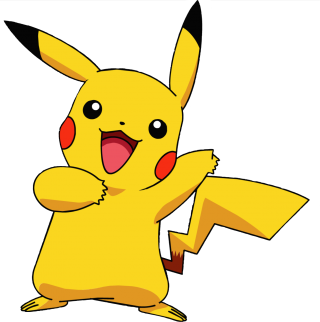

In [61]:
image = predict_pokemon("pikachu.png")

display(image)

1. Gengar: 99.63%
2. Haunter: 0.18%
3. Pupitar: 0.05%
4. Rhydon: 0.05%
5. Tyranitar: 0.01%


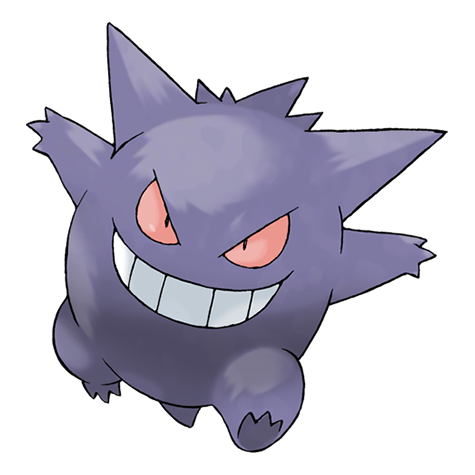

In [62]:
image = predict_pokemon("gengar.png")

display(image)

1. Plusle: 99.82%
2. Minun: 0.18%
3. Slowpoke: 0.00%
4. Deerling: 0.00%
5. Buneary: 0.00%


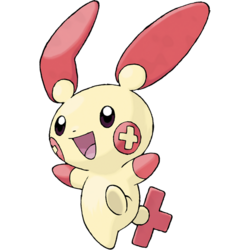

In [63]:
image = predict_pokemon("plusle.png")

display(image)